# Parameter-Efficient Fine-Tuning: LoRA Foundations & HuggingFace PEFT

## 1. Overview
Full fine-tuning of modern Large Language Models (LLMs) requires modifying all billions of parameters during backpropagation. This creates massive computational bottlenecks:
- **Optimizer Memory**: AdamW stores 16 bytes per parameter (weights, gradients, first and second moments). A 7B model needs about 112 GB (16 bytes × 7B) before activations.
- **Storage Explosion**: Storing full model checkpoints for every task or domain is unsustainable.

**Low-Rank Adaptation (LoRA)** overcomes this by freezing the pretrained model weights $W_0 \in \mathbb{R}^{d \times k}$ and injecting trainable rank decomposition matrices:
$$W = W_0 + \Delta W = W_0 + \frac{\alpha}{r} (B \cdot A)$$
where $B \in \mathbb{R}^{d \times r}$, $A \in \mathbb{R}^{r \times k}$, and rank $r \ll \min(d, k)$.

### What This Notebook Covers:
1. **Mathematical Foundations**: Low-rank decomposition, parameter savings, and gradient dynamics.
2. **LoRA Simulation from Scratch**: Forward pass, backward updates, and timing benchmarks in pure NumPy/PyTorch.
3. **Production PEFT Integration**: Using HuggingFace `peft` with `LoraConfig` and `get_peft_model`.
4. **Fine-Tuning on Transformers**: Adapting a transformer classifier while training about 1% of its parameters (the adapters alone are about 0.2%).

---
## 2. Low-Rank Decomposition: Math & Simulation

Consider a weight matrix $W \in \mathbb{R}^{1000 \times 1000}$ ($1,000,000$ parameters).
With LoRA rank $r=10$:
- Matrix $A \in \mathbb{R}^{10 \times 1000}$ ($10,000$ parameters)
- Matrix $B \in \mathbb{R}^{1000 \times 10}$ ($10,000$ parameters)
- **Total trainable parameters**: $20,000$ (a **$98\%$ reduction**!).

Following the slides, $A$ starts as a Gaussian and $B$ starts at zero, so $\Delta W = \frac{\alpha}{r}BA = 0$ and training begins exactly at the pretrained model. The forward pass is $h = W_0 x + \frac{\alpha}{r} B A x$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import tracemalloc
import sys

### Helpers

In [2]:
def make_weights(d_in, d_out, rank):
    """Return frozen W0 (d_out x d_in), A (rank x d_in, Gaussian) and B (d_out x rank, zeros).

    Notation follows the slides: W0 in R^{d x k}, A in R^{r x k}, B in R^{d x r}
    with d = d_out and k = d_in.
    """
    W0 = np.random.randn(d_out, d_in).astype(np.float32)
    A = (np.random.randn(rank, d_in) / np.sqrt(d_in)).astype(np.float32)
    B = np.zeros((d_out, rank), dtype=np.float32)
    return W0, A, B

### Fine-tuning Simulation

In [3]:
# Each step: forward pass  h = x @ W0^T                      (full fine-tuning: W is trained)
#            backward pass: grad_W = upstream^T @ x           <- full d_out x d_in matrix
#            parameter update: W -= lr * grad_W               <- touches all d_in * d_out params

def full_finetuning_steps(W, x_batch, n_steps=20, lr=1e-3):
    W = W.copy()
    upstream = np.ones((x_batch.shape[0], W.shape[0]), dtype=np.float32)
    for _ in range(n_steps):
        grad_W = upstream.T @ x_batch          # shape: (d_out, d_in), the full gradient
        W -= lr * grad_W
    return W


# ── LoRA fine-tuning simulation ───────────────────────────────────────────────
# Slide notation: h = W0 x + (alpha/r) B A x, with W0 frozen, A in R^{r x k}, B in R^{d x r}.
# Each step (batch form, g = upstream gradient of shape (batch, d)):
#   grad_B = (alpha/r) * g^T (x A^T)         -> (d, r)   small
#   grad_A = (alpha/r) * (B^T g^T) x         -> (r, k)   small
# Only A and B are updated; W0 never receives a gradient.

def lora_finetuning_steps(W0, A, B, x_batch, n_steps=20, lr=1e-3, alpha=16):
    A, B = A.copy(), B.copy()
    scale = alpha / A.shape[0]
    upstream = np.ones((x_batch.shape[0], W0.shape[0]), dtype=np.float32)
    for _ in range(n_steps):
        xA = x_batch @ A.T                              # (batch, r), small intermediate
        grad_B = scale * (upstream.T @ xA)              # (d, r)
        grad_A = scale * ((B.T @ upstream.T) @ x_batch) # (r, k)
        B -= lr * grad_B
        A -= lr * grad_A
    return A, B

In [4]:
# Sanity check: the hand-written LoRA gradients match finite differences.
def lora_loss(W0, A, B, x, alpha):
    h = x @ W0.T + (alpha / A.shape[0]) * (x @ A.T) @ B.T
    return h.sum()                                   # upstream gradient = ones

rng = np.random.default_rng(0)
d, k, r, alpha = 6, 5, 2, 4
W0t = rng.normal(size=(d, k)); At = rng.normal(size=(r, k)); Bt = rng.normal(size=(d, r)); xt = rng.normal(size=(3, k))
scale = alpha / r
g = np.ones((3, d))
grad_B = scale * (g.T @ (xt @ At.T)); grad_A = scale * ((Bt.T @ g.T) @ xt)

def numeric(M, loss_fn, eps=1e-6):
    out = np.zeros_like(M)
    for idx in np.ndindex(*M.shape):
        Mp, Mm = M.copy(), M.copy(); Mp[idx] += eps; Mm[idx] -= eps
        out[idx] = (loss_fn(Mp) - loss_fn(Mm)) / (2 * eps)
    return out

num_B = numeric(Bt, lambda M: lora_loss(W0t, At, M, xt, alpha))
num_A = numeric(At, lambda M: lora_loss(W0t, M, Bt, xt, alpha))
print("max |grad_B - numeric|:", np.abs(grad_B - num_B).max())
print("max |grad_A - numeric|:", np.abs(grad_A - num_A).max())

max |grad_B - numeric|: 2.6555966314845136e-09
max |grad_A - numeric|: 3.258005421002963e-09


**What to look for.** Both differences should be about 1e-8 or smaller. If they were large, the simulation above would be timing the wrong computation.

### Measurement

In [5]:
def measure_performance(d=1000, rank=10, batch_size=32, n_steps=20):
    W, A, B = make_weights(d, d, rank)   # W0 (d x d), A (r x d), B (d x r)
    x_batch  = np.random.randn(batch_size, d).astype(np.float32)

    # --- Full fine-tuning ---
    tracemalloc.start()
    t0 = time.perf_counter()
    full_finetuning_steps(W, x_batch, n_steps)
    full_time = time.perf_counter() - t0
    _, full_peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # --- LoRA fine-tuning ---
    tracemalloc.start()
    t0 = time.perf_counter()
    lora_finetuning_steps(W, A, B, x_batch, n_steps, alpha=2 * rank)
    lora_time = time.perf_counter() - t0
    _, lora_peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    return {
        'full_finetuning_time':   full_time,
        'lora_finetuning_time':   lora_time,
        'full_finetuning_memory': full_peak_bytes / 1024,   # KB
        'lora_finetuning_memory': lora_peak_bytes / 1024,
    }

### Plotting

In [6]:
def plot_performance_comparison(perf, rank, d):
    labels = ['Full Fine-Tuning', f'LoRA (rank={rank})']
    times  = [perf['full_finetuning_time'],   perf['lora_finetuning_time']]
    memory = [perf['full_finetuning_memory'],  perf['lora_finetuning_memory']]

    # Annotate with trainable-parameter counts
    full_params = d * d
    lora_params = d * rank + rank * d   # A + B

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    bars1 = ax1.bar(labels, times, color=['steelblue', 'orange'])
    ax1.set_title('Computation Time\n(gradient steps, lower = better)', fontsize=12)
    ax1.set_ylabel('Time (seconds)')
    for bar, val in zip(bars1, times):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.02,
                 f'{val:.4f}s', ha='center', va='bottom', fontsize=10)

    bars2 = ax2.bar(labels, memory, color=['steelblue', 'orange'])
    ax2.set_title('Peak Memory Usage\n(tracemalloc, lower = better)', fontsize=12)
    ax2.set_ylabel('Memory (KB)')
    for bar, val in zip(bars2, memory):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.02,
                 f'{val:.1f} KB', ha='center', va='bottom', fontsize=10)

    param_labels = [f'{full_params:,} params', f'{lora_params:,} params\n({100*lora_params/full_params:.1f}% of full)']
    for ax, pl_list in [(ax1, param_labels), (ax2, param_labels)]:
        for bar, pl in zip(ax.patches, pl_list):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()*0.5,
                    pl, ha='center', va='center', fontsize=8, color='white', fontweight='bold')

    plt.tight_layout()
    plt.show()

### Execution

=== Performance Comparison ===
Full fine-tuning  — time: 0.0152s  |  peak memory: 11845.3 KB
LoRA fine-tuning  — time: 0.0028s  |  peak memory: 361.6 KB

Trainable params  — Full: 1,000,000  |  LoRA: 20,000  (2.0% of full)
Speed-up          : 5.40x
Memory reduction  : 32.76x


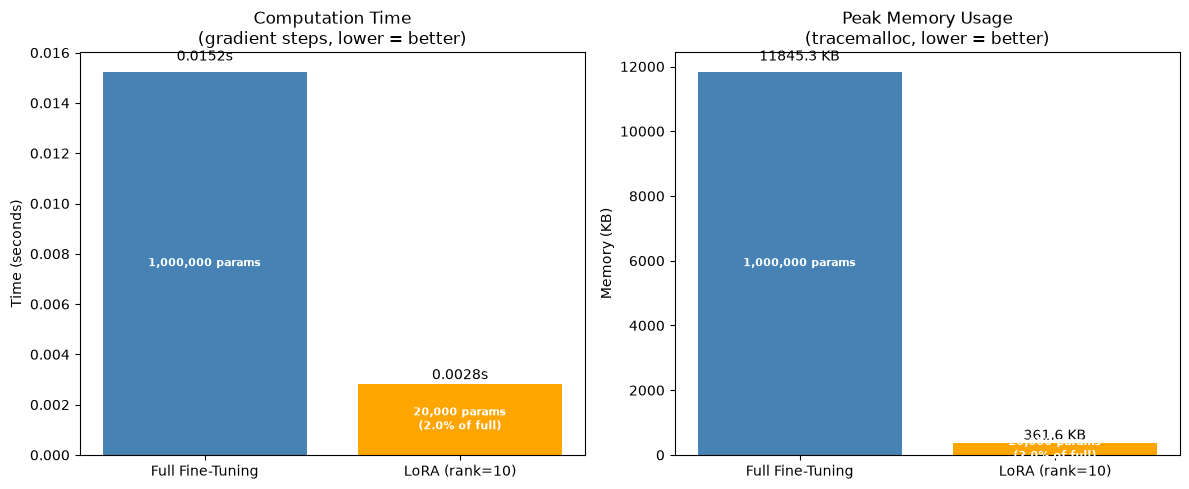

In [7]:
D    = 1000   # weight matrix dimension (d_in = d_out = 1000)
RANK = 10    # LoRA rank  (only 2×10K = 20K trainable params vs 1M for full)

perf = measure_performance(d=D, rank=RANK, batch_size=32, n_steps=20)

print("=== Performance Comparison ===")
print(f"Full fine-tuning  — time: {perf['full_finetuning_time']:.4f}s  |  peak memory: {perf['full_finetuning_memory']:.1f} KB")
print(f"LoRA fine-tuning  — time: {perf['lora_finetuning_time']:.4f}s  |  peak memory: {perf['lora_finetuning_memory']:.1f} KB")
print()

full_params = D * D
lora_params = 2 * D * RANK
print(f"Trainable params  — Full: {full_params:,}  |  LoRA: {lora_params:,}  ({100*lora_params/full_params:.1f}% of full)")
print(f"Speed-up          : {perf['full_finetuning_time'] / perf['lora_finetuning_time']:.2f}x")
print(f"Memory reduction  : {perf['full_finetuning_memory'] / perf['lora_finetuning_memory']:.2f}x")

plot_performance_comparison(perf, RANK, D)

---
## 3. Production PEFT with HuggingFace `peft` & Transformers

We now apply LoRA to a real transformer model using the industry-standard `peft` library. We configure `LoraConfig`, attach low-rank adapters to query/value projection layers, and measure parameter efficiency.

In [8]:
import numpy as np
import pandas as pd
from datasets import Dataset
from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
from sklearn.model_selection import train_test_split
import evaluate
import torch
from peft import get_peft_model, LoraConfig, TaskType
import os
from datasets import load_dataset

## Data Preparation Functions

First, let's create helper functions to prepare and process our data.

In [9]:
def prepare_imdb_dataset(max_samples=2000):
    """Load and prepare IMDB dataset for sentiment analysis.
    
    Args:
        max_samples (int): Maximum number of samples to use (for memory efficiency)
    Returns:
        pd.DataFrame: DataFrame with 'text' and 'label' columns
    """
    # Load IMDB dataset
    dataset = load_dataset("imdb")
    
    # Convert to pandas and sample if needed
    train_df = pd.DataFrame({
        'text': dataset['train']['text'],
        'label': dataset['train']['label']
    })
    
    if max_samples and max_samples < len(train_df):
        train_df = train_df.sample(n=max_samples, random_state=42)
    
    # Clean text (remove HTML tags, excessive spaces)
    train_df['text'] = train_df['text'].apply(lambda x: x.replace('<br />', ' '))
    train_df['text'] = train_df['text'].apply(lambda x: ' '.join(x.split()))
    
    return train_df

In [10]:
def prepare_datasets(df, test_size=0.2, val_size=0.1):
    """Split data into train, validation, and test sets and convert to HF datasets.
    
    Args:
        df (pd.DataFrame): Input DataFrame with 'text' and 'label' columns
        test_size (float): Proportion of data for test set
        val_size (float): Proportion of training data for validation
    Returns:
        tuple: (train_dataset, val_dataset, test_dataset)
    """
    # First split into train+val and test
    train_val_df, test_df = train_test_split(df, test_size=test_size, random_state=42)
    
    # Then split train into train and val
    train_df, val_df = train_test_split(train_val_df, test_size=val_size, random_state=42)
    
    # Convert to HuggingFace datasets
    train_dataset = Dataset.from_pandas(train_df)
    val_dataset = Dataset.from_pandas(val_df)
    test_dataset = Dataset.from_pandas(test_df)
    
    return train_dataset, val_dataset, test_dataset

In [11]:
def tokenize_and_format_dataset(dataset, tokenizer):
    """Tokenize and format dataset with fixed padding settings and proper label handling."""
    def preprocess_function(examples):
        tokenized = tokenizer(
            examples["text"],
            padding='max_length',
            truncation=True,
            max_length=128,
            return_tensors=None
        )
        # Add labels to tokenized output
        tokenized['labels'] = examples['label']
        return tokenized
    
    # Remove unused columns and tokenize
    formatted_dataset = dataset.map(
        preprocess_function,
        batched=True,
        remove_columns=dataset.column_names
    )

    # Set format for PyTorch
    formatted_dataset.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "labels"]
    )
    
    return formatted_dataset

## Model Architecture and Training Strategy
Our implementation focuses on these key aspects:
1. Base Model: DistilBERT (lighter version of BERT)
2. Adaptation Method: LoRA for efficient fine-tuning
3. Training Setup:
   - CPU-based training configuration
   - Proper batch size for memory constraints
   - Evaluation strategy for monitoring
   - Optimization choice for stability

### Important Considerations:
- Tokenizer settings must match between training and inference
- Model states (train/eval) need proper management
- Validation metrics should guide model selection
- Data collation needs consistent padding strategy

In [12]:
def get_training_args(output_dir="./results", num_epochs=3):
    """Training arguments for a small CPU run (requires transformers >= 4.41; logging_dir was removed in v5)."""
    return TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        warmup_steps=100,
        weight_decay=0.01,
        logging_steps=50,
        eval_strategy="steps",
        eval_steps=100,
        save_strategy="steps",
        save_steps=100,
        load_best_model_at_end=True,
        metric_for_best_model="accuracy",
        remove_unused_columns=True,
        use_cpu=True,
        optim="adamw_torch",  # use PyTorch's AdamW
        report_to="none"  # no external logger
    )

In [13]:
def compute_metrics(eval_pred):
    """Compute evaluation metrics.
    
    Args:
        eval_pred: Tuple of predictions and labels
    Returns:
        dict: Dictionary containing metrics
    """
    metric = evaluate.load("accuracy")
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

In [14]:
def get_lora_config():
    """Configure LoRA parameters for efficient fine-tuning."""
    return LoraConfig(
        r=8,  # rank of the update matrices
        lora_alpha=16,  # scaling factor
        target_modules=["q_lin", "v_lin"],  # layers to apply LoRA
        lora_dropout=0.1,
        bias="none",
        task_type=TaskType.SEQ_CLS  # can be TOKEN_CLS for token classification
    )

def setup_model_for_training():
    """Setup model with LoRA configuration for training."""
    # Initialize base model
    model = DistilBertForSequenceClassification.from_pretrained(
        'distilbert-base-uncased',
        num_labels=2,
        device_map='cpu'  # force CPU
    )
    
    # Add LoRA configuration
    lora_config = get_lora_config()
    model = get_peft_model(model, lora_config)
    
    # Set model to training mode
    model.train()
    
    # Print trainable parameters
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Trainable parameters: {trainable_params}")
    print(f"Total parameters: {total_params}")
    print(f"Trainable%: {100 * trainable_params / total_params:.2f}%")
    
    return model

def prepare_model_and_data(df, model_name='distilbert-base-uncased'):
    """Prepare model, tokenizer, and datasets for training."""
    # Initialize tokenizer
    tokenizer = DistilBertTokenizer.from_pretrained(model_name)
    
    # Create datasets
    train_dataset, val_dataset, test_dataset = prepare_datasets(df)
    
    # Format datasets with proper label handling
    train_formatted = tokenize_and_format_dataset(train_dataset, tokenizer)
    val_formatted = tokenize_and_format_dataset(val_dataset, tokenizer)
    
    # Initialize model
    model = DistilBertForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2,
        device_map='cpu'
    )
    
    # Add LoRA configuration
    lora_config = get_lora_config()
    model = get_peft_model(model, lora_config)
    
    # Create data collator
    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        padding='max_length',
        max_length=128
    )
    
    return model, tokenizer, train_formatted, val_formatted, data_collator

# Create dataset using IMDB
df = prepare_imdb_dataset(max_samples=2000)

# Prepare model and data
model, tokenizer, train_formatted, val_formatted, data_collator = prepare_model_and_data(df)

# Setup training arguments
training_args = get_training_args()

# Initialize trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_formatted,
    eval_dataset=val_formatted,
    compute_metrics=compute_metrics,
    data_collator=data_collator,
)

Using the latest cached version of the dataset since imdb couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'plain_text' at /Users/apujari/.cache/huggingface/datasets/imdb/plain_text/0.0.0/e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Tue Oct 13 16:13:58 2026).


Map:   0%|          | 0/1440 [00:00<?, ? examples/s]

Map:   0%|          | 0/160 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


**About the loading report.** When the cell above loads DistilBERT, Transformers prints a report. It is expected, not an error:

- `UNEXPECTED` keys (`vocab_projector`, `vocab_transform`, `vocab_layer_norm`) belong to the masked-language-modeling head used in pretraining. We load a classifier instead, so they are dropped.
- `MISSING` keys (`pre_classifier`, `classifier`) are the new sentiment head. The pretrained checkpoint has none, so it starts with random weights and is learned during training. PEFT trains this head in full alongside the LoRA adapters, which is why the trainable-parameter count printed later is larger than the adapters alone.

Predictions before `trainer.train()` are therefore not meaningful, because the head is still random.

## Training Process and Monitoring
The training implementation includes:
1. Proper metric computation
2. Regular evaluation steps
3. Model checkpointing
4. Progress tracking
5. Resource management

### Best Practices for Training:
- Monitor training/validation losses
- Check for overfitting signs
- Validate predictions periodically
- Save best model checkpoints
- Use appropriate learning rate schedules

In [15]:
# Start training
trainer.train()

Step,Training Loss,Validation Loss,Accuracy
100,0.689642,0.672155,0.531250
200,0.545951,0.467084,0.806250
300,0.439148,0.417235,0.806250
400,0.375193,0.411625,0.800000
500,0.444932,0.402334,0.812500
540,0.444932,0.400305,0.806250


TrainOutput(global_step=540, training_loss=0.49738077587551544, metrics={'train_runtime': 186.4218, 'train_samples_per_second': 23.173, 'train_steps_per_second': 2.897, 'total_flos': 145518559395840.0, 'train_loss': 0.49738077587551544, 'epoch': 3.0})

## Inference and Model Usage
Key aspects of the inference pipeline:
1. Proper model state management
2. Consistent tokenization settings
3. Confidence score calculation
4. Error handling and validation

### Best Practices for Inference:
- Always use eval() mode for prediction
- Match preprocessing with training
- Handle edge cases and errors
- Consider batch processing for efficiency
- Monitor prediction confidence

In [16]:
def predict_sentiment(text, model, tokenizer):
    """Make prediction with improved error handling and confidence scores."""
    # Ensure model is in eval mode
    model.eval()
    
    try:  
        # Proper tokenizer settings
        inputs = tokenizer(
            text, 
            return_tensors="pt",
            padding='max_length',
            truncation=True,
            max_length=128
        )
        
        inputs = {k: v.to('cpu') for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.nn.functional.softmax(outputs.logits, dim=1)
            prediction = torch.argmax(probs, dim=1).item()
            confidence = probs[0][prediction].item()
        
        label = "positive" if prediction == 1 else "negative"
        return label, f"{confidence:.2%}"
        
    except Exception as e:  # Fixed syntax: removed curly brace, added colon
        print(f"Error during prediction: {str(e)}")
        return "error", "0%"

# Test the model
test_texts = [
    "I really enjoyed the product",
    "This was a terrible experience",
    "The service was absolutely amazing",
    "I am very disappointed with the quality"
]

print("Model Predictions:")
for text in test_texts:
    sentiment, confidence = predict_sentiment(text, model, tokenizer)
    print(f"Text: {text}")
    print(f"Sentiment: {sentiment} (Confidence: {confidence})\n")


Model Predictions:
Text: I really enjoyed the product
Sentiment: positive (Confidence: 88.47%)

Text: This was a terrible experience
Sentiment: negative (Confidence: 60.34%)

Text: The service was absolutely amazing
Sentiment: positive (Confidence: 91.45%)

Text: I am very disappointed with the quality
Sentiment: negative (Confidence: 57.40%)



## If the Predictions Look Weak

This run is deliberately small: a 2,000-review IMDB subset, 128 tokens per review, 3 epochs on CPU. Expect decent but not state-of-the-art accuracy, and short or ambiguous test sentences can still be misclassified. Things to try:

1. **More data or epochs**: raise `max_samples` in `prepare_imdb_dataset` or `num_epochs` in `get_training_args`.
2. **LoRA capacity**: increase `r` (and `lora_alpha` with it), or add more `target_modules` such as `k_lin`, `out_lin`, `lin1` and `lin2`.
3. **Learning rate**: LoRA usually tolerates a higher learning rate than full fine-tuning; compare a few values.
4. **Check the metric**: read the validation accuracy printed during training before judging individual predictions.

## Model Statistics Summary

Let's analyze the impact of LoRA on model parameters and memory footprint:

In [17]:
def print_model_statistics(model, model_name='distilbert-base-uncased'):
    """Print detailed statistics about model parameters and LoRA impact."""
    # Get original model size
    base_model = DistilBertForSequenceClassification.from_pretrained(model_name)
    base_params = sum(p.numel() for p in base_model.parameters())
    
    # Get LoRA params
    lora_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    
    # Calculate sizes
    base_size_mb = base_params * 4 / 1024 / 1024  # assuming float32
    lora_size_mb = lora_params * 4 / 1024 / 1024
    
    print("=== Model Statistics ===")
    print(f"Base Model Parameters: {base_params:,}")
    print(f"LoRA Trainable Parameters: {lora_params:,}")
    print(f"Parameter Efficiency: {lora_params/base_params:.2%}")
    print(f"\nModel Sizes:")
    print(f"Base Model: {base_size_mb:.2f} MB")
    print(f"LoRA Adapters: {lora_size_mb:.2f} MB")
    print(f"Size Efficiency: {lora_size_mb/base_size_mb:.2%}")
    
    # Show LoRA configuration
    if hasattr(model, 'peft_config'):
        print(f"\nLoRA Configuration:")
        print(f"Rank (r): {model.peft_config['default'].r}")
        print(f"Alpha: {model.peft_config['default'].lora_alpha}")
        print(f"Target Modules: {model.peft_config['default'].target_modules}")

# Print statistics
print_model_statistics(model)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


=== Model Statistics ===
Base Model Parameters: 66,955,010
LoRA Trainable Parameters: 739,586
Parameter Efficiency: 1.10%

Model Sizes:
Base Model: 255.41 MB
LoRA Adapters: 2.82 MB
Size Efficiency: 1.10%

LoRA Configuration:
Rank (r): 8
Alpha: 16
Target Modules: {'v_lin', 'q_lin'}


Read the printed statistics above against these reference points for `distilbert-base-uncased` with `r=8` on `q_lin` and `v_lin`:

### Parameter Comparison
- **Base model**: about 67M parameters (66.96M including the new classification head).
- **LoRA adapters alone**: 6 layers × 2 modules × r × (768 + 768) = 147,456 parameters, about 0.22% of the base model.
- **Printed trainable count**: higher than 147,456, because `TaskType.SEQ_CLS` also trains the newly initialised classification head (PEFT keeps it via `modules_to_save`). The exact head size depends on the PEFT version.

### Memory Footprint
- Trainable weights in float32 take 4 bytes each, so the adapters alone are about 0.6 MB, against about 255 MB for the base model.

### LoRA Configuration
- **Rank (r=8)**: size of the low-rank factors; lower rank is smaller but less expressive.
- **Alpha (16)**: the update is scaled by α/r (here 2), so it controls how strongly LoRA changes the base model. Setting α to about 2r is a common starting point, not a rule.
- **Target modules**: `q_lin` and `v_lin` are the query and value projections of each attention block.

## 4. Summary & Key Takeaways

1. **Low-Rank Hypothesis**: Weight updates $\Delta W$ during adaptation have a very low intrinsic dimension (Aghajanyan et al.), allowing rank $r \in [8, 64]$ to match full fine-tuning performance.
2. **Zero Inference Latency**: At deployment, adapter weights can be permanently merged into the base model ($W = W_0 + \frac{\alpha}{r}BA$), yielding zero added latency during forward inference.
3. **Multi-Tenant Serving**: A single base model instance in VRAM can serve dozens of task-specific LoRA adapters dynamically swapped in RAM.
4. **QLoRA**: Combining 4-bit NormalFloat (NF4) base model quantization with LoRA lets a 7B model fine-tune in about 4 to 6 GB of GPU memory, and a 65B model fit on a single 48 GB GPU (Dettmers et al., 2023).